# Learning Probability Flows with Neural Networks
## Linear stochastic interpolant — Albergo & Vanden-Eijnden

## Imports and initial.

In [1]:
import numpy as np
import torch
import torch.nn as nn

import matplotlib.pyplot as plt

torch.manual_seed(1337)
np.random.seed(228)

device = torch.device("mps")

TRAIN_STEPS = 10000
N_RK4 = 100

## Distributions

In [2]:
def sample_nomal(n):
    return torch.randn(n, 2, device=device)

def sample_eight_gaussians(n):
    k = torch.randint(0, 8, (n,), device=device)
    angles = 2 * torch.pi * k / 8
    centers = 4 * torch.stack([torch.cos(angles), torch.sin(angles)], dim=1)
    return centers + 0.5 * torch.randn(n, 2, device=device)

def sample_spiral(n):
    phi = 3 * torch.pi * torch.rand(n, device=device)
    r = 0.3 + 0.28 * phi
    points = torch.stack([r * torch.cos(phi), r * torch.sin(phi)], dim=1)
    return points + 0.12 * torch.randn(n, 2, device=device)


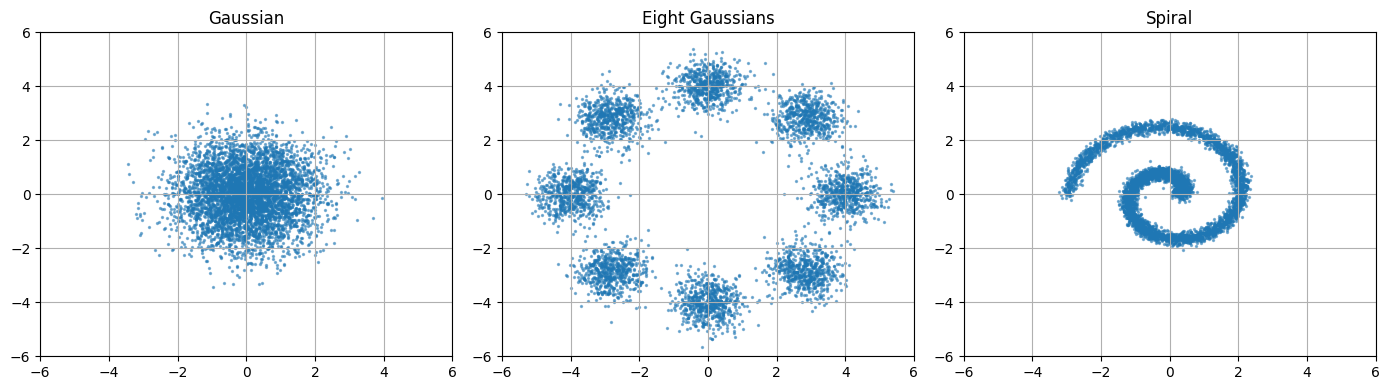

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, sampler, title in zip(axes, [sample_nomal, sample_eight_gaussians, sample_spiral], ["Gaussian", "Eight Gaussians", "Spiral"]):
    xy = sampler(5000).cpu().numpy()
    ax.scatter(xy[:, 0], xy[:, 1], s=2, alpha=0.5)
    ax.set(title=title, xlim=(-6, 6), ylim=(-6, 6))
    ax.grid()
plt.tight_layout()
plt.show()

## interpolant
$X_t=(1-t)X_0+tX_1$, so $\dot X_t=X_1-X_0$.

In [4]:
def interpolant(x0, x1, t):
    xt = (1.0 - t) * x0 + t * x1
    dxt = x1 - x0
    return xt, dxt

x0_test = sample_nomal(128)
x1_test = sample_eight_gaussians(128)
a, _ = interpolant(x0_test, x1_test, torch.zeros(128, 1, device=device))
b, _ = interpolant(x0_test, x1_test, torch.ones(128, 1, device=device))


## Neural-network
The network takes $(x_1,x_2,t)$ and returns $(v_1,v_2)$.

In [5]:
class VelocityNetwork(nn.Module):
    def __init__(self, hidden_dim=256):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(3, hidden_dim), 
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim), 
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim), 
            nn.ReLU(),
            nn.Linear(hidden_dim, 2))

    def forward(self, x, t):
        return self.network(torch.cat([x, t], dim=1))

model_test = VelocityNetwork(256).to(device)

## loss function
$\mathbb E[\|v_\theta(X_t,t)-(X_1-X_0)\|^2]$, taken from paper.

In [6]:
def velocity_mse_loss(model, x0, x1, t):
    xt, dxt = interpolant(x0, x1, t)
    v_pred = model(xt, t)
    return (v_pred - dxt).square().sum(dim=1).mean()

loss_test = velocity_mse_loss(model_test, sample_nomal(32), sample_eight_gaussians(32), torch.rand(32, 1, device=device))


## Training function

In [7]:
def train_flow(source_sampler, target_sampler, *, steps=TRAIN_STEPS):
    model = VelocityNetwork(256).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=10e-3)
    losses = []
    model.train()

    for step in range(steps):
        x0 = source_sampler(1024)
        x1 = target_sampler(1024)
        t = torch.rand(1024, 1, device=device)

        optimizer.zero_grad()
        loss = velocity_mse_loss(model, x0, x1, t)
        loss.backward()
        optimizer.step()
        losses.append(loss.item())

        if (step + 1) % 1000 == 0:
            print(f"{step+1:5d}/{steps}  loss is: {loss.item():.4f}")
    model.eval()
    return model, losses

## Train normal to eight Gaussians

In [8]:
model_eight, loss_eight = train_flow(sample_nomal, sample_eight_gaussians)

 1000/10000  loss is: 8.1326
 2000/10000  loss is: 8.1199
 3000/10000  loss is: 8.1247
 4000/10000  loss is: 7.9295
 5000/10000  loss is: 7.5832
 6000/10000  loss is: 7.7129
 7000/10000  loss is: 8.3870
 8000/10000  loss is: 7.6512
 9000/10000  loss is: 8.6348
10000/10000  loss is: 8.1402


## Train normal to spiral

In [9]:
model_spiral, loss_spiral = train_flow(sample_nomal, sample_spiral)

 1000/10000  loss is: 3.6106
 2000/10000  loss is: 3.5351
 3000/10000  loss is: 3.6539
 4000/10000  loss is: 3.6626
 5000/10000  loss is: 3.7294
 6000/10000  loss is: 3.4804
 7000/10000  loss is: 3.7105
 8000/10000  loss is: 3.7655
 9000/10000  loss is: 3.6012
10000/10000  loss is: 3.5962


## loss curves

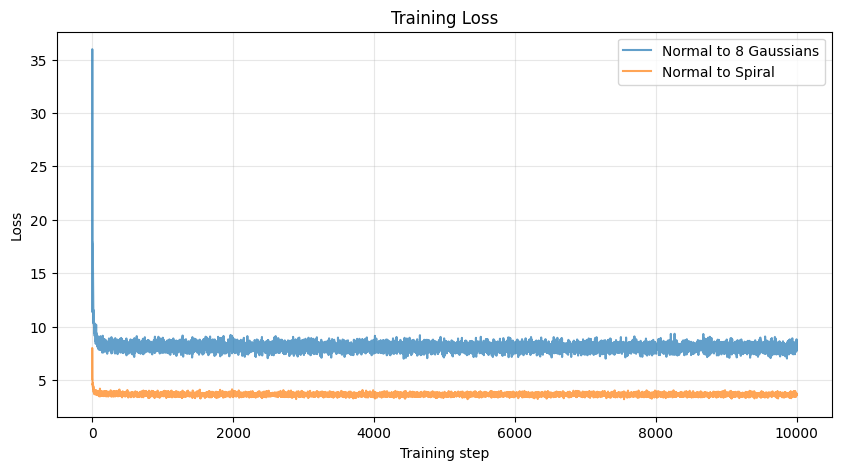

In [10]:
plt.figure(figsize=(10, 5))

plt.plot(loss_eight, label="Normal to 8 Gaussians", alpha=0.7)
plt.plot(loss_spiral, label="Normal to Spiral", alpha=0.7)

plt.xlabel("Training step")
plt.ylabel("Loss")
plt.title("Training Loss")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

## RK4 integration

In [11]:
@torch.no_grad()
def rk4_integrate(model, x0, n_steps=100, save_trajectory=False):
    model.eval()
    x = x0.clone()
    h = 1.0 / n_steps
    trajectory = [x.clone()] if save_trajectory else None

    for i in range(n_steps):
        t = torch.full((x.shape[0], 1), i*h, dtype=x.dtype, device=x.device)
        k1 = model(x, t)
        k2 = model(x + 0.5*h*k1, t + 0.5*h)
        k3 = model(x + 0.5 * h*k2, t + 0.5*h)
        k4 = model(x + h*k3, t + h)
        x = x + (h / 6.0)*(k1 + 2*k2 + 2*k3 + k4)
        if save_trajectory:
            trajectory.append(x.clone())

    if save_trajectory:
        return x, torch.stack(trajectory, dim=0)
    return x

## Generated vs target distributions

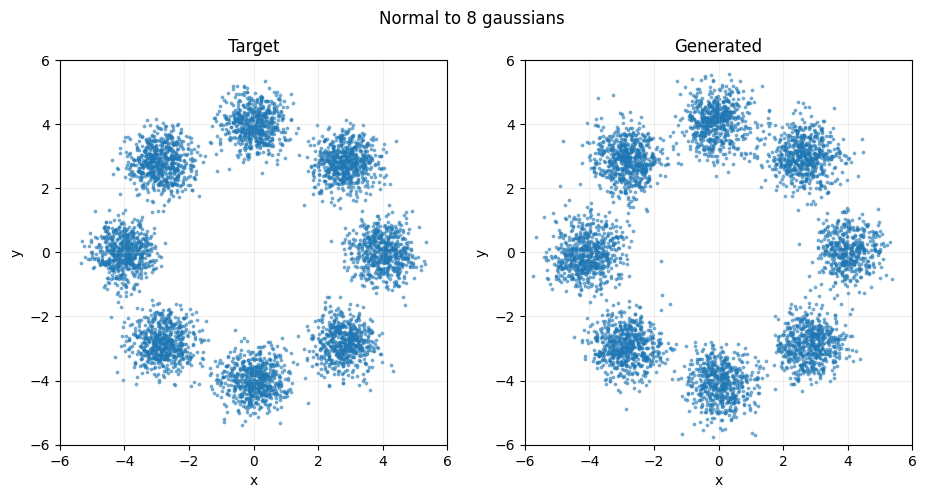

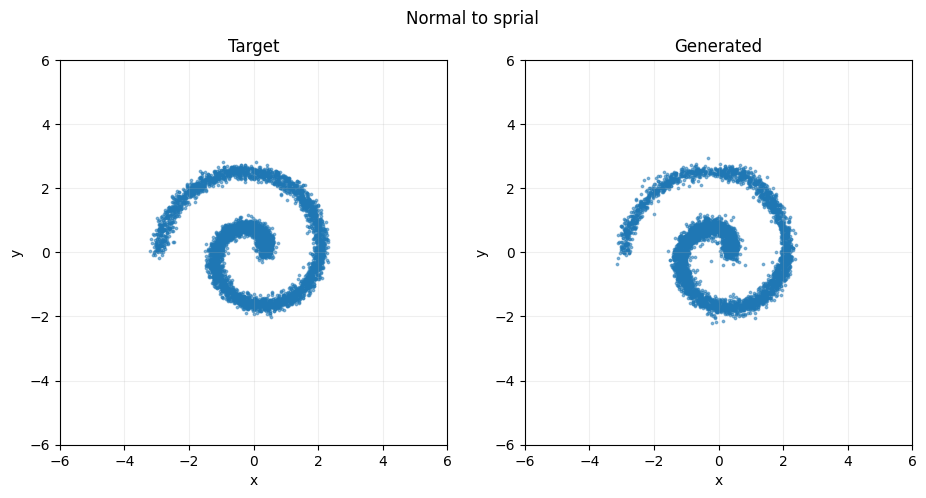

In [12]:
@torch.no_grad()
def plot_target_vs_generated(model, source_sampler, target_sampler, title, n=5000, n_steps=N_RK4):
    x0 = source_sampler(n)
    generated = rk4_integrate(model, x0, n_steps=n_steps)
    target = target_sampler(n)

    fig, axes = plt.subplots(1, 2, figsize=(11, 5))
    for ax, points, label in zip(axes, [target, generated], ["Target", "Generated"]):
        xy = points.cpu().numpy()
        ax.scatter(xy[:, 0], xy[:, 1], s=3, alpha=0.5)
        ax.set(title=label, xlim=(-6, 6), ylim=(-6, 6), xlabel="x", ylabel="y")
        ax.grid(alpha=0.2)
    fig.suptitle(title)
    plt.show()

plot_target_vs_generated(model_eight, sample_nomal, sample_eight_gaussians, "Normal to 8 gaussians")
plot_target_vs_generated(model_spiral, sample_nomal, sample_spiral, "Normal to sprial")

## Trajectories

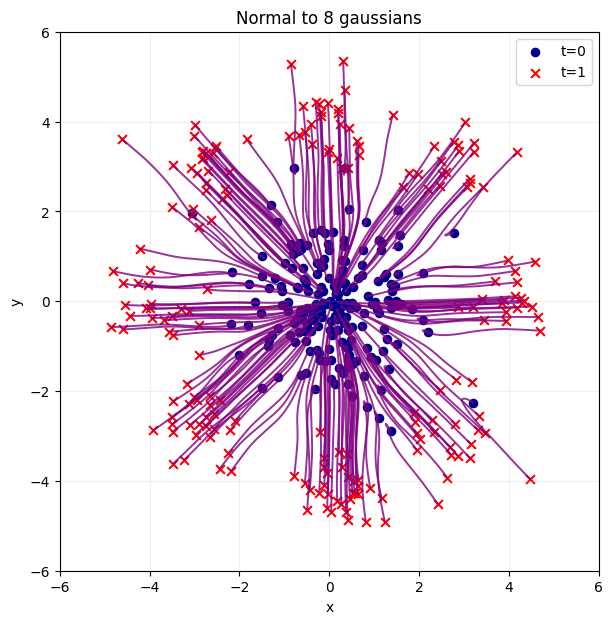

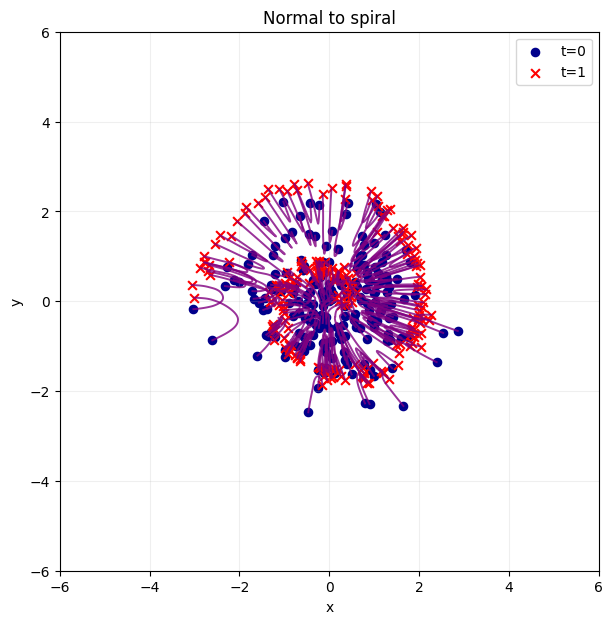

In [13]:
@torch.no_grad()
def plot_trajectories(model, source_sampler, title, n=200, n_steps=100):
    x0 = source_sampler(n)
    _, trajectory = rk4_integrate(model, x0, n_steps=n_steps, save_trajectory=True)
    paths = trajectory.cpu().numpy()  # (time, particles, xy)

    fig, ax = plt.subplots(figsize=(7, 7))
    for j in range(n):
        ax.plot(paths[:, j, 0], paths[:, j, 1], lw=1.4, alpha=0.8, color='purple')
    ax.scatter(paths[0, :, 0], paths[0, :, 1], s=35, c="darkblue", label="t=0")
    ax.scatter(paths[-1, :, 0], paths[-1, :, 1], s=40, c="red", marker="x", label="t=1")
    ax.set(title=title, xlabel="x", ylabel="y", xlim=(-6,6), ylim=(-6,6))
    ax.set_aspect("equal")
    ax.legend()
    ax.grid(alpha=0.2)
    plt.show()

plot_trajectories(model_eight, sample_nomal, "Normal to 8 gaussians")
plot_trajectories(model_spiral, sample_nomal, "Normal to spiral")

## Velocity vector fields at $t=0$, $0.5$, $1$

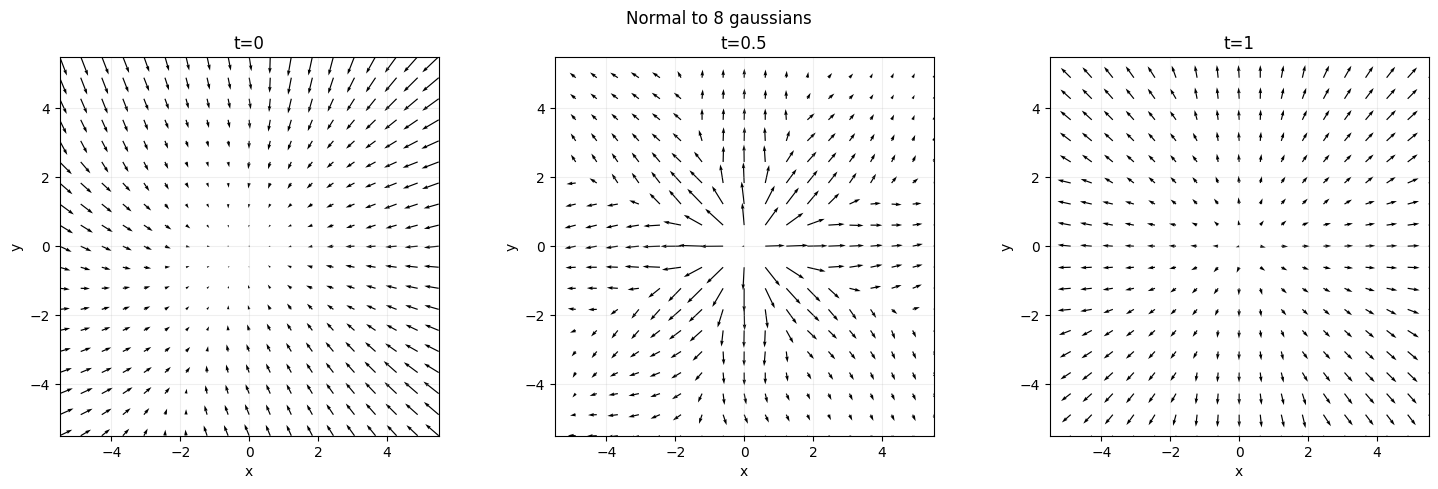

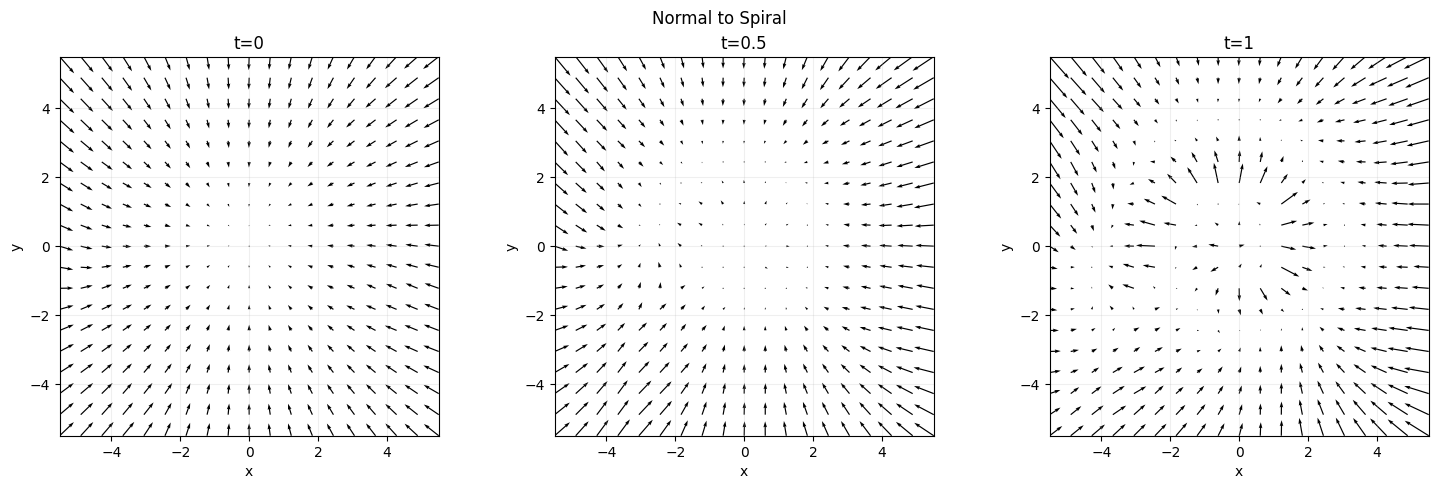

In [14]:
@torch.no_grad()
def plot_velocity_fields(model, title, extent=5.5, grid_n=19):
    axis = np.linspace(-extent, extent, grid_n)
    xx, yy = np.meshgrid(axis, axis)
    xy = torch.tensor(np.stack([xx.ravel(), yy.ravel()], axis=1),
                      dtype=torch.float32, device=device)
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
    for ax, time in zip(axes, [0.0, 0.5, 1.0]):
        t = torch.full((xy.shape[0], 1), time, device=device)
        v = model(xy, t).cpu().numpy().reshape(grid_n, grid_n, 2)
        ax.quiver(xx, yy, v[:, :, 0], v[:, :, 1], angles="xy")
        ax.set(title=f"t={time:g}", xlim=(-extent,extent), ylim=(-extent,extent),
               xlabel="x", ylabel="y")
        ax.set_aspect("equal")
        ax.grid(alpha=0.2)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

plot_velocity_fields(model_eight, "Normal to 8 gaussians")
plot_velocity_fields(model_spiral, "Normal to Spiral")

## RK4 step-number comparison, with identical initial points

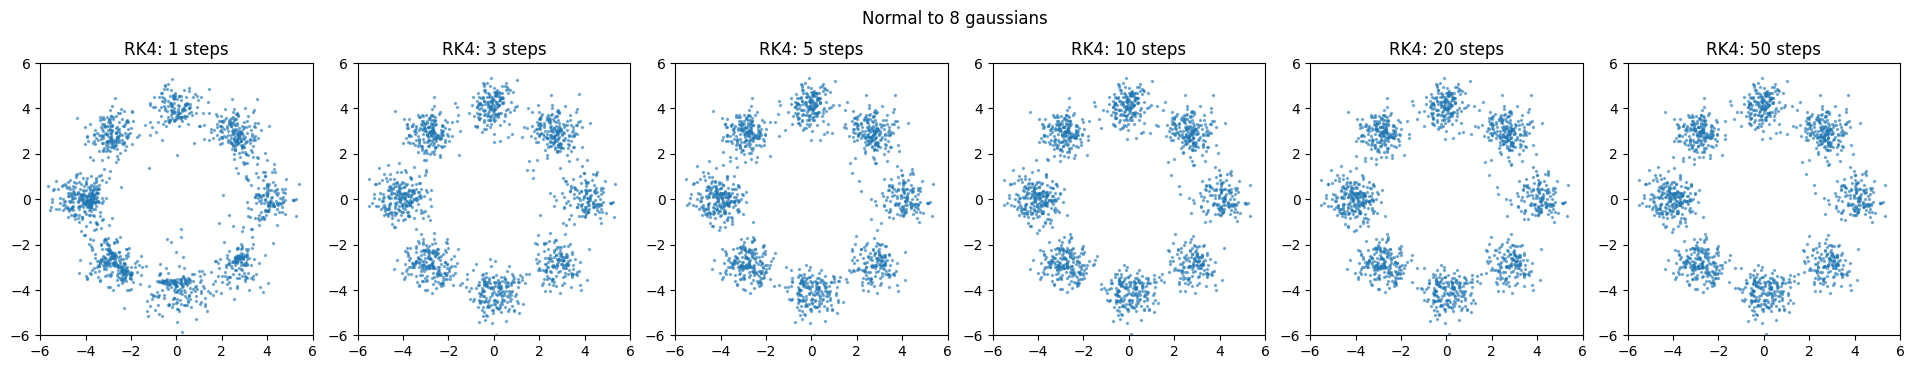

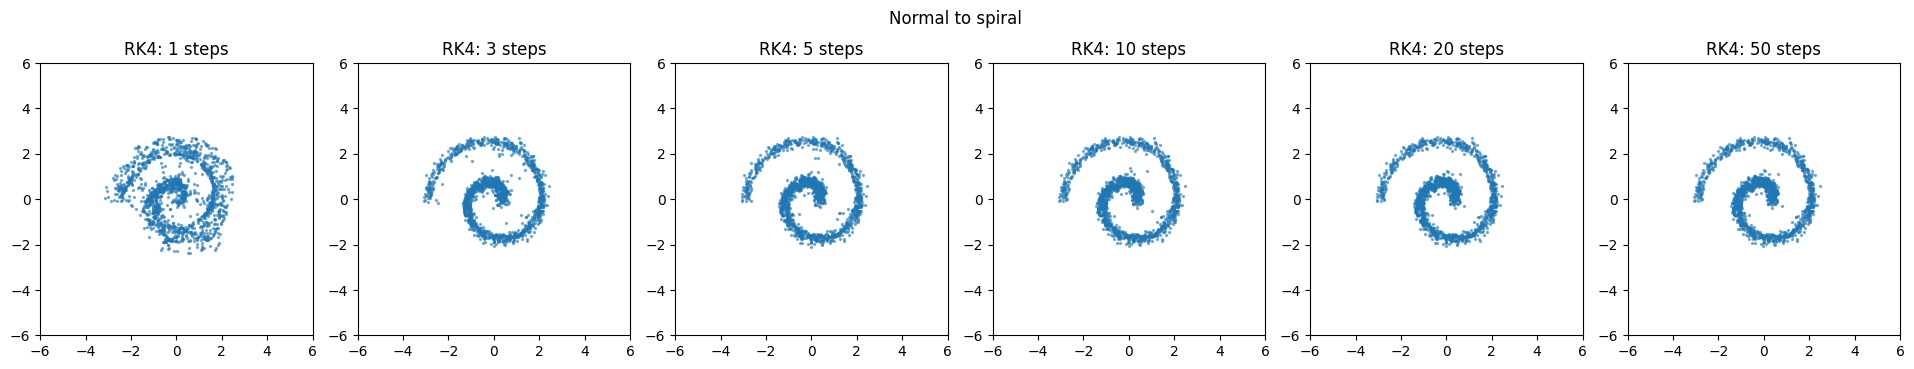

In [15]:
@torch.no_grad()
def rk4_convergence(model, source_sampler, title, n=1500,
                    steps=(1, 3, 5, 10, 20, 50), reference_steps=400):
    x0 = source_sampler(n) 
    ref = rk4_integrate(model, x0, n_steps=reference_steps)
    errors = []
    fig, axes = plt.subplots(1, len(steps), figsize=(3.2*len(steps), 3.6))
    for ax, N in zip(axes, steps):
        y = rk4_integrate(model, x0, n_steps=N)
        error = ((y - ref).square().sum(dim=1).mean().sqrt()).item()
        errors.append(error)
        xy = y.cpu().numpy()
        ax.scatter(xy[:,0], xy[:,1], s=2, alpha=0.5)
        ax.set(title=f"RK4: {N} steps", xlim=(-6,6), ylim=(-6,6))
        ax.set_aspect("equal")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

rk4_convergence(model_eight, sample_nomal, "Normal to 8 gaussians")
rk4_convergence(model_spiral, sample_nomal, "Normal to spiral")

## Compare interpolant with learned ODE

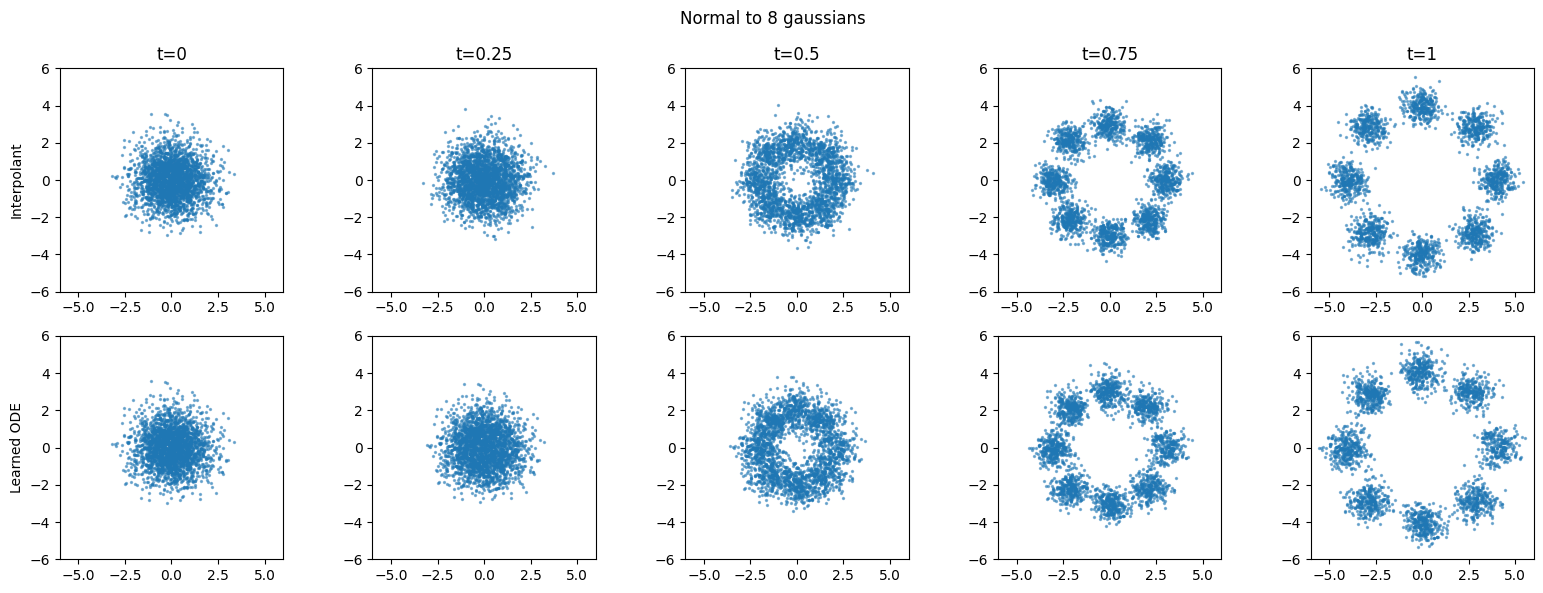

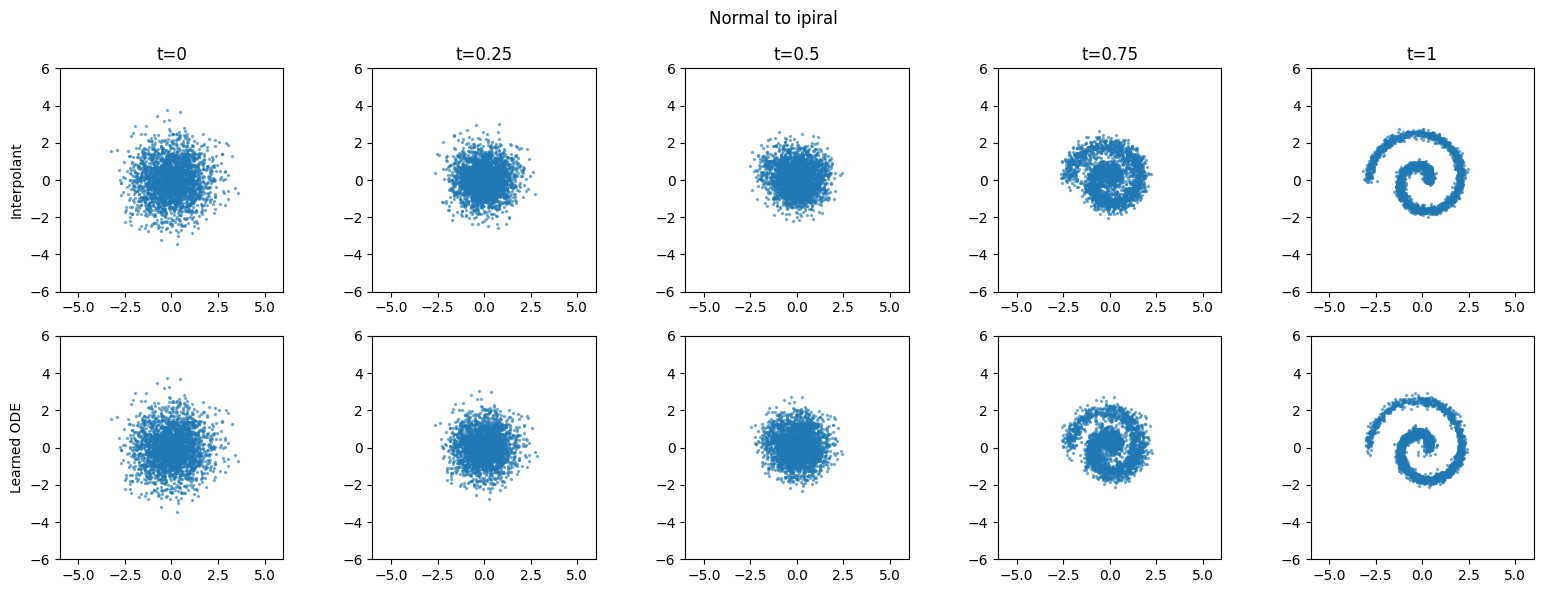

In [ ]:
@torch.no_grad()
def compare_interpolant_and_ode(model, source_sampler, target_sampler, title, n=2500, n_steps=100):

    x0 = source_sampler(n)
    x1 = target_sampler(n)
    _, traj = rk4_integrate(model, x0, n_steps=n_steps, save_trajectory=True)
    times = [0, 0.25, 0.5, 0.75, 1.0]
    fig, axes = plt.subplots(2, len(times), figsize=(16, 6))
    for j, time in enumerate(times):
        t = torch.full((n,1), time, device=device)
        direct, _ = interpolant(x0, x1, t)
        ode = traj[round(time*n_steps)]
        for row, pts in enumerate((direct, ode)):
            a = pts.cpu().numpy()
            axes[row, j].scatter(a[:,0], a[:,1], s=2, alpha=.5)
            axes[row, j].set(xlim=(-6,6), ylim=(-6,6))
            axes[row, j].set_aspect("equal")
        axes[0, j].set_title(f"t={time:g}")
    axes[0,0].set_ylabel("Interpolant")
    axes[1,0].set_ylabel("Learned ODE")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

compare_interpolant_and_ode(model_eight, sample_nomal, sample_eight_gaussians,"Normal to 8 gaussians")
compare_interpolant_and_ode(model_spiral, sample_nomal, sample_spiral, "Normal to spiral")

## 8 Gaussians to Spiral


 1000/10000  loss is: 9.6436
 2000/10000  loss is: 8.4230
 3000/10000  loss is: 8.6798
 4000/10000  loss is: 9.1289
 5000/10000  loss is: 8.5252
 6000/10000  loss is: 8.5231
 7000/10000  loss is: 8.8204
 8000/10000  loss is: 8.6253
 9000/10000  loss is: 8.5489
10000/10000  loss is: 8.1611


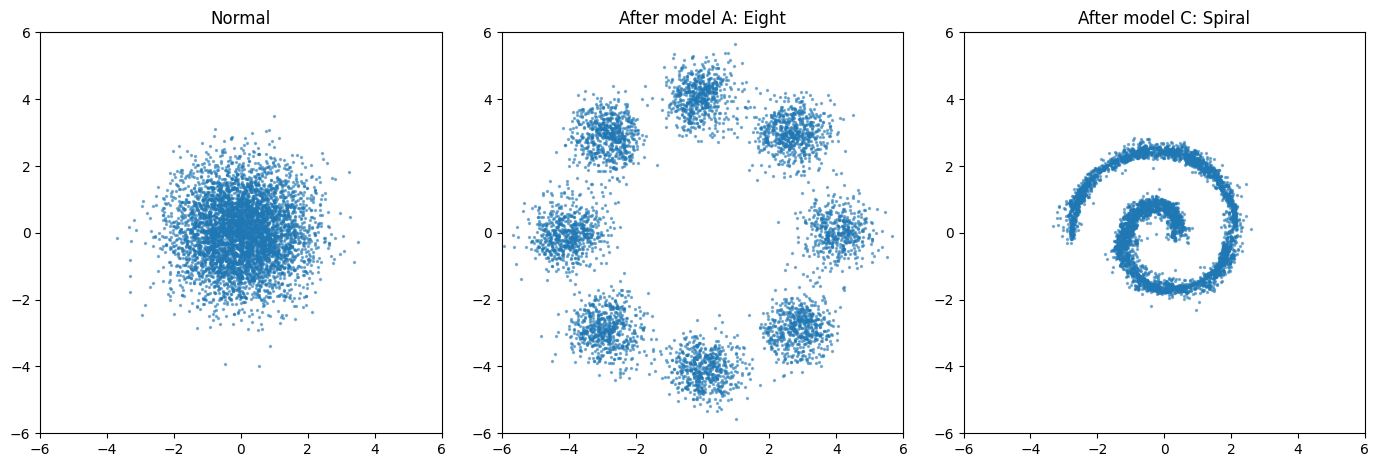

In [17]:

model_eight_to_spiral, loss_eight_to_spiral = train_flow(
    sample_eight_gaussians, sample_spiral
)
x0 = sample_nomal(5000)
x_eight = rk4_integrate(model_eight, x0, n_steps=N_RK4)
x_spiral_chain = rk4_integrate(model_eight_to_spiral, x_eight, n_steps=N_RK4)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
for ax, points, name in zip(
    axes, [x0, x_eight, x_spiral_chain],
    ["Normal", "After model A: Eight", "After model C: Spiral"]
):
    xy = points.cpu().numpy()
    ax.scatter(xy[:,0], xy[:,1], s=2, alpha=0.5)
    ax.set(title=name, xlim=(-6,6), ylim=(-6,6))
    ax.set_aspect("equal")
plt.tight_layout()
plt.show()